In [7]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join('..')))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from src.models.structured.models import get_tree_models,train_model
from src.models.structured.evaluation import evaluate_classification,plot_confusion_matrix

In [3]:
df = pd.read_csv("../data/processed/train_engineered.csv")

df["TransactionDT"].value_counts()

C:\Users\Anmoy\AppData\Local\Temp\ipykernel_13060\3021472524.py:1: DtypeWarning: Columns (416,420) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/processed/train_engineered.csv")


TransactionDT
9474817     8
4397066     5
7236588     5
11576951    5
2073296     4
           ..
15810372    1
15810379    1
15810398    1
15810402    1
15810063    1
Name: count, Length: 573349, dtype: int64

In [5]:
X = df.drop(columns=['isFraud', 'TransactionID', 'TransactionDT'])
y = df['isFraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)
X_train.shape,X_test.shape,y_train.shape,y_test.shape

((472432, 634), (118108, 634), (472432,), (118108,))

In [8]:
print("Encoding categorical features...")

cat_cols = X_train.select_dtypes(include=['object', 'category']).columns

# Initialize encoder
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)

# Fill NaNs and convert to string
train_cat = X_train[cat_cols].fillna('unknown').astype(str)
test_cat = X_test[cat_cols].fillna('unknown').astype(str)

# Fit on train, transform both
X_train[cat_cols] = oe.fit_transform(train_cat)
X_test[cat_cols] = oe.transform(test_cat)

Encoding categorical features...


In [11]:
# Find columns with infinite values
inf_cols = X_train.columns[np.isinf(X_train).any()].tolist()
print(f"Columns containing inf/-inf: {len(inf_cols)}")
print(inf_cols[:10])

Columns containing inf/-inf: 1
['D15_log']


In [12]:
# 1. Replace all +/- infinity with NaN
X_train = X_train.replace([np.inf, -np.inf], np.nan)
test_engineered = X_test.replace([np.inf, -np.inf], np.nan)

# 2. Ensure float16 columns are cast to float32 (sklearn and tree models require >= float32)
float16_cols = X_train.select_dtypes(include=['float16']).columns
if len(float16_cols) > 0:
    X_train[float16_cols] = X_train[float16_cols].astype(np.float32)
    X_test[float16_cols] = X_test[float16_cols].astype(np.float32)

print("Infinite values cleared and float types normalized.")

Infinite values cleared and float types normalized.


In [14]:
# Load uninitialized models
models = get_tree_models()
import joblib

Training Random Forest...

--- Random Forest Performance ---
Accuracy: 0.8450
Precision: 0.1534
Recall: 0.7590
F1-Score: 0.2552
ROC-AUC: 0.8778


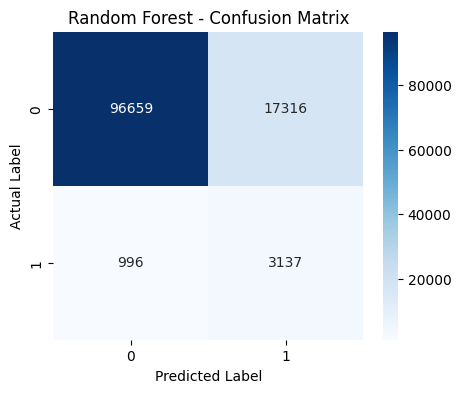

In [15]:
print("Training Random Forest...")
rf_model = models['Random Forest']

# Train and save
rf_fitted = train_model(rf_model, X_train, y_train)
joblib.dump(rf_fitted, '../models/random_forest_model.pkl')

# Predict
rf_pred = rf_fitted.predict(X_test)
rf_pred_proba = rf_fitted.predict_proba(X_test)[:, 1]

# Evaluate
evaluate_classification(y_test, rf_pred, rf_pred_proba, model_name="Random Forest")
plot_confusion_matrix(y_test, rf_pred, model_name="Random Forest")

Training XGBoost...

--- XGBoost Performance ---
Accuracy: 0.9807
Precision: 0.7826
Recall: 0.6209
F1-Score: 0.6924
ROC-AUC: 0.9491


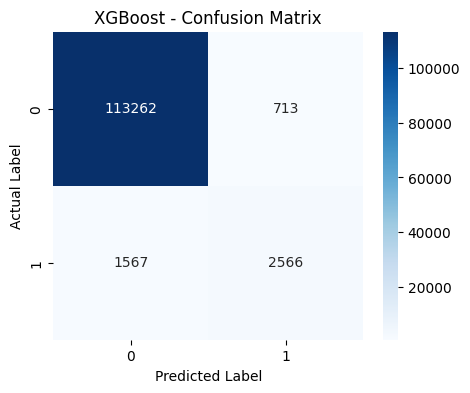

In [16]:
print("Training XGBoost...")
xgb_model = models['XGBoost']

# Train and save
xgb_fitted = train_model(xgb_model, X_train, y_train)
joblib.dump(xgb_fitted, '../models/xgboost_model.pkl')

# Predict
xgb_pred = xgb_fitted.predict(X_test)
xgb_pred_proba = xgb_fitted.predict_proba(X_test)[:, 1]

# Evaluate
evaluate_classification(y_test, xgb_pred, xgb_pred_proba, model_name="XGBoost")
plot_confusion_matrix(y_test, xgb_pred, model_name="XGBoost")

Training LightGBM...
[LightGBM] [Info] Number of positive: 16530, number of negative: 455902
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.184686 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 58921
[LightGBM] [Info] Number of data points in the train set: 472432, number of used features: 629
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000

--- LightGBM Performance ---
Accuracy: 0.8879
Precision: 0.2113
Recall: 0.8064
F1-Score: 0.3348
ROC-AUC: 0.9268


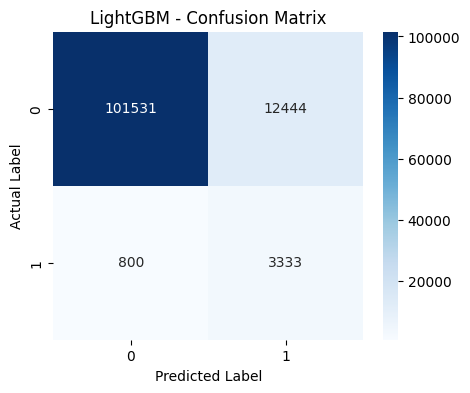

In [18]:
print("Training LightGBM...")
lgbm_model = models['LightGBM']

# Train and save
lgbm_fitted = train_model(lgbm_model, X_train, y_train)
joblib.dump(lgbm_fitted, '../models/lightgbm_model.pkl')

# Predict
lgbm_pred = lgbm_fitted.predict(X_test)
lgbm_pred_proba = lgbm_fitted.predict_proba(X_test)[:, 1]

# Evaluate
evaluate_classification(y_test, lgbm_pred, lgbm_pred_proba, model_name="LightGBM")
plot_confusion_matrix(y_test, lgbm_pred, model_name="LightGBM")